# Chapter 2 · The Black–Scholes formula three ways: interactive demos

Companion to Chapter 2 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/02-black-scholes.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The test case is $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price 7.36429). The pricing equation is
reduced to the heat equation $\partial_s u=\frac12\partial_{\xi\xi}u$ by $V=Ke^{-rT}u(s,\xi)$ with $s=\sigma^2T$ and
$\xi=\log(S/K)+\nu T$, $\nu=r-y-\sigma^2/2$; the call's heat solution starts from $u_0(\xi)=(e^\xi-1)^+$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import warnings
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown

from mfe230d import bs
from mfe230d import transforms as tr
from mfe230d import impliedvol as iv
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

warnings.simplefilter("ignore")
use_style()
GREEN = "#1BAF7A"
P = bs.TEST_CASE

## 1. One price, three ways

The call payoff grows like $e^\xi$ and has no Fourier transform; damped by $e^{-a\xi}$ with $a>1$ it does, and the
price is the integral of Proposition 2.5 along the line $\operatorname{Im}z=-a$. Left: the (real part of the) integrand
against the frequency $\omega$. Middle: the error of the trapezoidal rule against the step $h$, with the
nearest-pole estimate $Se^{-yT}e^{-2\pi(a-1)/h}$. Right: the error of the fixed Talbot rule for the Laplace transform
against the number of nodes $M$. The title compares the three prices.

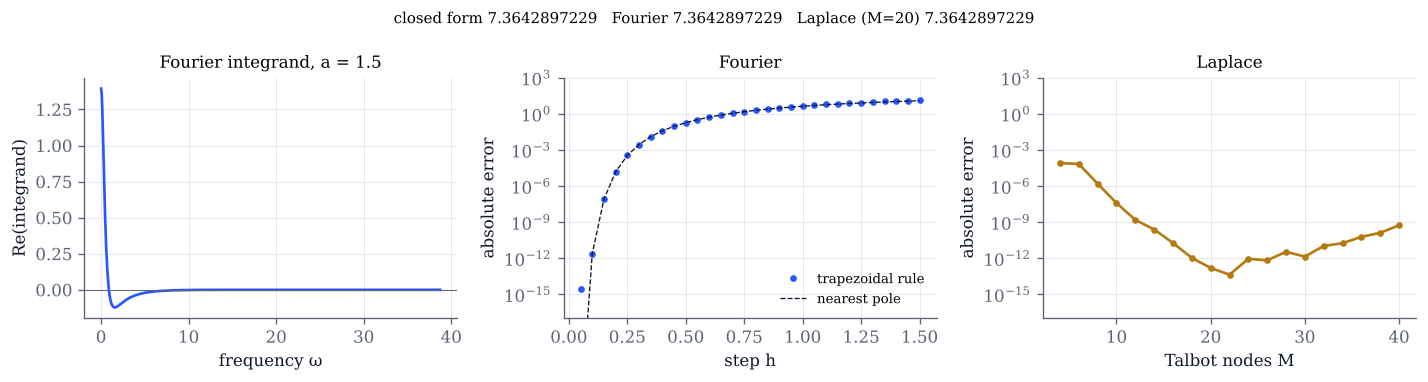

In [2]:
def three_ways(K=100.0, T=1.0, sigma=0.20, a=1.5):
    p = dict(P, K=K, T=T, sigma=sigma)
    exact = float(bs.call(**p))
    s, xi = tr.heat_variables(**p)
    s, xi = float(s), float(xi)
    om = np.linspace(0, np.sqrt(60 / s), 600)
    z = om - 1j * a
    g = (np.exp(1j * om * xi) * tr.call_payoff_transform(z) * tr.heat_kernel_transform(z, s)).real
    fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(12, 3.2))
    ax.plot(om, g, color=COBALT)
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(xlabel="frequency ω", ylabel="Re(integrand)", title=f"Fourier integrand, a = {a:g}")
    hs = np.linspace(0.05, 1.5, 30)
    err = [max(abs(float(tr.fourier_call(**p, a=a, h=h)) - exact), 1e-17) for h in hs]
    bx.semilogy(hs, err, "o", color=COBALT, ms=3, label="trapezoidal rule")
    bx.semilogy(hs, p["S"] * np.exp(-p["y"] * T) * np.exp(-2 * np.pi * (a - 1) / hs), "--", color=INK,
                lw=0.8, label="nearest pole")
    bx.set(xlabel="step h", ylabel="absolute error", ylim=(1e-17, 1e3), title="Fourier"); bx.legend(fontsize=8)
    Ms = np.arange(4, 41, 2)
    errL = [max(abs(float(tr.laplace_call(**p, M=M)) - exact), 1e-17) for M in Ms]
    cx.semilogy(Ms, errL, "o-", color=GOLD, ms=3)
    cx.set(xlabel="Talbot nodes M", ylabel="absolute error", ylim=(1e-17, 1e3), title="Laplace")
    fig.suptitle(f"closed form {exact:.10f}   Fourier {float(tr.fourier_call(**p, a=a)):.10f}   "
                 f"Laplace (M=20) {float(tr.laplace_call(**p)):.10f}", fontsize=9)
    fig.tight_layout(); plt.show()

three_ways()

In [3]:
# Explore: short maturities make the integrand decay slowly; large dampings amplify rounding at long maturities.
interact(three_ways,
         K=FloatSlider(value=100.0, min=50.0, max=200.0, step=5.0, continuous_update=False, description="K"),
         T=FloatLogSlider(value=1.0, base=10, min=-2, max=1.5, step=0.1, continuous_update=False, description="T"),
         sigma=FloatSlider(value=0.20, min=0.05, max=1.0, step=0.05, continuous_update=False, description="σ"),
         a=FloatSlider(value=1.5, min=1.1, max=6.0, step=0.1, continuous_update=False, description="damping a"));

## 2. The Greeks and their relations

Proposition 2.7: the call's delta, gamma, vega and theta against the spot (from `bs.greeks`, with theta per year as
$\partial_t V$). Below the plot, the largest residual of each of the five relations over the spot grid:
homogeneity $V=S\Delta+K\partial_KV$, carry $\rho_r+\rho_y=-TV$, vega-gamma $\mathcal V=\sigma TS^2\Gamma$,
time $\Theta=-(r\rho_r+y\rho_y+\sigma\mathcal V/2)/T$ and the pricing equation. They hold to rounding error for every input.

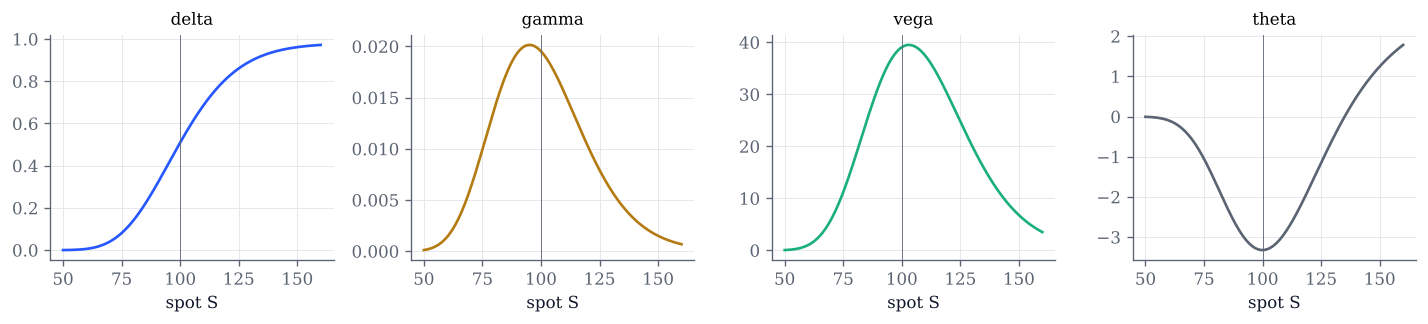

largest residuals:  homogeneity 4.3e-14,  carry 0.0e+00,  vega-gamma 7.1e-15,  time 1.3e-15,  pricing equation 1.3e-15


In [4]:
def greeks_plot(T=1.0, sigma=0.20, r=0.01, y=0.02, kind="call"):
    S = np.linspace(50, 160, 221)
    K = 100.0
    g = bs.greeks(S, K, T, r, y, sigma, kind)
    V = (bs.call if kind == "call" else bs.put)(S, K, T, r, y, sigma)
    dm = bs.d_pm(S, K, T, r, y, sigma)[1]
    dK = -np.exp(-r * T) * bs.norm_cdf(dm) + (0 if kind == "call" else np.exp(-r * T))
    fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
    for ax, k, col in zip(axes, ("delta", "gamma", "vega", "theta"), (COBALT, GOLD, GREEN, GREY)):
        ax.plot(S, g[k], color=col); ax.set(xlabel="spot S", title=k); ax.axvline(K, color=GREY, lw=0.5)
    fig.tight_layout(); plt.show()
    res = {
        "homogeneity": np.max(np.abs(V - S * g["delta"] - K * dK)),
        "carry": np.max(np.abs(g["rho_r"] + g["rho_y"] + T * V)),
        "vega-gamma": np.max(np.abs(g["vega"] - sigma * T * S**2 * g["gamma"])),
        "time": np.max(np.abs(g["theta"] + (r * g["rho_r"] + y * g["rho_y"] + 0.5 * sigma * g["vega"]) / T)),
        "pricing equation": np.max(np.abs(g["theta"] + (r - y) * S * g["delta"] + 0.5 * sigma**2 * S**2 * g["gamma"] - r * V)),
    }
    print("largest residuals:  " + ",  ".join(f"{k} {v:.1e}" for k, v in res.items()))

greeks_plot()

In [5]:
# Explore: when can the call theta be positive? Try a large yield y and a deep in-the-money spot.
interact(greeks_plot,
         T=FloatLogSlider(value=1.0, base=10, min=-2, max=1, step=0.1, continuous_update=False, description="T"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.01, min=-0.02, max=0.10, step=0.005, continuous_update=False, description="r"),
         y=FloatSlider(value=0.02, min=0.0, max=0.10, step=0.005, continuous_update=False, description="y"),
         kind=Dropdown(options=["call", "put"], value="call", description="kind"));

## 3. Newton's method for the implied volatility

The normalised call price $c(m,w)=e^mN(m/w+w/2)-N(m/w-w/2)$, with $m=\log(F/K)$ and total volatility
$w=\sigma\sqrt T$, is convex below the inflection point $w^*=\sqrt{2|m|}$ and concave above (Proposition 2.9).
Newton on the price converges monotonically from $w^*$ but can jump to negative values from other starts;
Newton on $\log c$ (with halving when a step is not positive) converges from any start. The figure shows the
first iterates of both from your starting point $w_0$, and of Newton on the price from $w^*$; the right panel
shows the errors $|w_n-w_{\mathrm{imp}}|$.

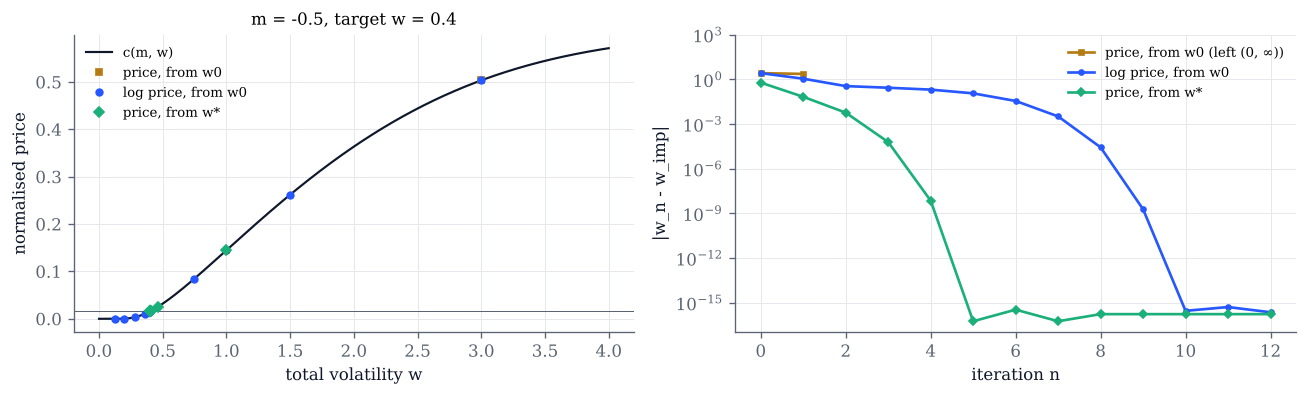

In [6]:
def log_newton_path(m, log_beta, w0, n=12):
    # log_beta comes from iv.log_normalised_call, so tiny prices do not underflow
    w = [w0]
    for _ in range(n):
        lc, dlc = iv.log_normalised_call(m, w[-1])
        new = w[-1] - (float(lc) - log_beta) / float(dlc)
        w.append(new if new > 0 else w[-1] / 2)
    return np.array(w)

def newton_demo(m=-0.5, w_true=0.4, w0=3.0):
    beta = float(iv.normalised_call(m, w_true))
    ws = float(iv.inflection_point(m))
    paths = {"price, from w0": iv.newton_iterates(m, beta, w0, 12),
             "log price, from w0": log_newton_path(m, float(iv.log_normalised_call(m, w_true)[0]), w0),
             "price, from w*": iv.newton_iterates(m, beta, ws, 12) if m != 0 else None}
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.4))
    w = np.linspace(1e-3, max(4.0, 1.2 * w0), 400)
    ax.plot(w, iv.normalised_call(m, w), color=INK, lw=1.3, label="c(m, w)")
    ax.axhline(beta, color=GREY, lw=0.6)
    if m != 0:
        ax.plot([ws], [iv.normalised_call(m, ws)], "o", color=INK, ms=4)
    for (lab, pth), col, mk in zip(paths.items(), (GOLD, COBALT, GREEN), ("s", "o", "D")):
        if pth is None:
            continue
        ok = np.isfinite(pth) & (pth > 0)
        ax.plot(pth[ok], iv.normalised_call(m, pth[ok]), mk, color=col, ms=4, label=lab)
        err = np.abs(pth - w_true)
        bx.semilogy(np.arange(len(pth))[np.isfinite(err)], np.maximum(err[np.isfinite(err)], 1e-17), mk + "-",
                    color=col, ms=3, label=lab + (" (left (0, ∞))" if (~ok).any() else ""))
    ax.set(xlabel="total volatility w", ylabel="normalised price", title=f"m = {m:g}, target w = {w_true:g}")
    ax.legend(fontsize=8)
    bx.set(xlabel="iteration n", ylabel="|w_n - w_imp|", ylim=(1e-17, 1e3)); bx.legend(fontsize=8)
    fig.tight_layout(); plt.show()

newton_demo()

In [7]:
# Explore: at m = 0 the price is concave everywhere; for m < 0 compare targets below and above w* = sqrt(2|m|).
interact(newton_demo,
         m=FloatSlider(value=-0.5, min=-2.0, max=0.0, step=0.05, continuous_update=False, description="m"),
         w_true=FloatLogSlider(value=0.4, base=10, min=-1.5, max=0.6, step=0.05, continuous_update=False,
                               description="target w"),
         w0=FloatLogSlider(value=3.0, base=10, min=-2, max=1, step=0.05, continuous_update=False, description="start w0"));

## Things to try

- In section 1, take $T=0.01$: how many Fourier nodes does the default rule use, and why? Then take $T=30$,
  $\sigma=0.8$ and raise the damping $a$: when does rounding spoil the Fourier price?
- In section 1, for which $M$ is the Talbot error smallest, and does that depend on the strike?
- In section 2, set $y=0.08$, $r=0$ and look at the call theta for large spots. Explain the sign with the forward.
- In section 3, set $m=0$, target $w=0.2$ and start $w_0=2$: what does Newton on the price do? Then move $w_0$ until it
  converges. Why does Newton on the log-price (with halving) converge from every start when $m\le0$?
- In section 3, take $m=-2$ and a small target $w=0.1$ (a price near $10^{-91}$): compare the number of iterations of Newton on the price from
  $w^*$ with that of Newton on the log-price.